In [1]:
!pip install --upgrade keras

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 10.7 MB/s eta 0:00:00
  Attempting uninstall: keras
    Found existing installation: keras 2.15.0
    Uninstalling keras-2.15.0:
      Successfully uninstalled keras-2.15.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.15.0 requires keras<2.16,>=2.15.0, but you have keras 3.0.5 which is incompatible.


In [2]:
import keras

print(keras.__version__)

3.0.5


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenet_1.00_224 (Functional)      │ (None, 7, 7, 1024)          │       3,228,864 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 7, 7, 1024)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1024)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 1024)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 10)                  │          10,250 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,239,114 (12.36 MB)

 Trainable params: 3,217,226 (12.27 MB)

 Non-trainable params: 21,888 (85.50 KB)

Epoch 1/17
235/235 - 37s - 157ms/step - accuracy: 0.5163 - loss: 1.4822 - val_accuracy: 0.7990 - val_loss: 0.6200
Epoch 2/17
235/235 - 15s - 65ms/step - accuracy: 0.7293 - loss: 0.7920 - val_accuracy: 0.8235 - val_loss: 0.5245
Epoch 3/17
235/235 - 10s - 41ms/step - accuracy: 0.7660 - loss: 0.6813 - val_accuracy: 0.8315 - val_loss: 0.4831
Epoch 4/17
235/235 - 9s - 38ms/step - accuracy: 0.7909 - loss: 0.6129 - val_accuracy: 0.8335 - val_loss: 0.4714
Epoch 5/17
235/235 - 8s - 34ms/step - accuracy: 0.7965 - loss: 0.5733 - val_accuracy: 0.8315 - val_loss: 0.4761
Epoch 6/17
235/235 - 9s - 37ms/step - accuracy: 0.8089 - loss: 0.5460 - val_accuracy: 0.8385 - val_loss: 0.4589
Epoch 7/17
235/235 - 11s - 47ms/step - accuracy: 0.8173 - loss: 0.5290 - val_accuracy: 0.8395 - val_loss: 0.4541
Epoch 8/17
235/235 - 8s - 35ms/step - accuracy: 0.8117 - loss: 0.5366 - val_accuracy: 0.8480 - val_loss: 0.4357
Epoch 9/17
235/235 - 8s - 36ms/step - accuracy: 0.8119 - loss: 0.5313 - val_accuracy: 0.8400 - val_

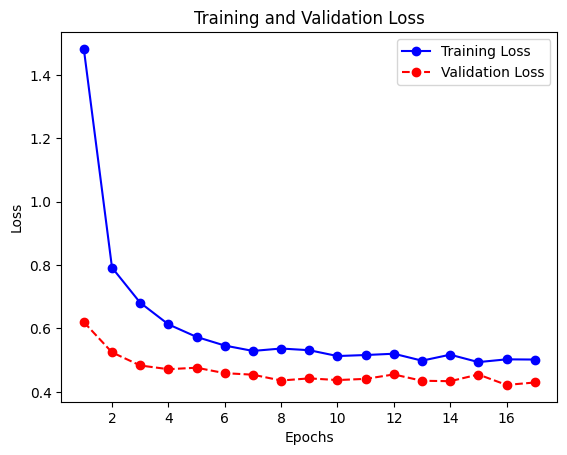

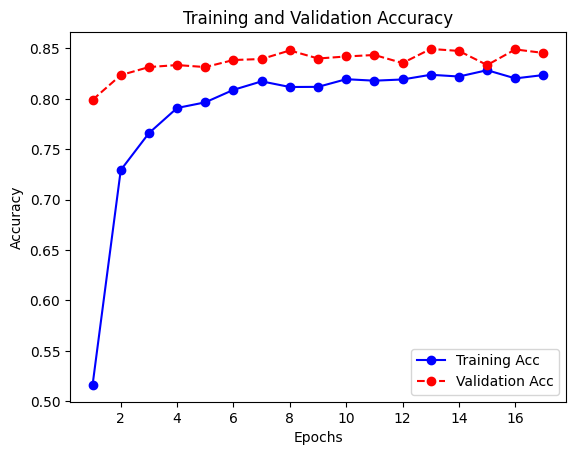

In [3]:
import numpy as np
from keras.datasets import cifar10
from keras.applications.mobilenet import MobileNet, preprocess_input
from keras import Sequential
from keras.layers import Input, Dense, Dropout, GlobalAveragePooling2D
import tensorflow as tf
import warnings

warnings.filterwarnings("ignore")
# 指定亂數種子
np.random.seed(10)
# 載入資料集
(X_train, y_train), (X_test, y_test) = cifar10.load_data()
# 打亂 2 個 Numpy 陣列
def randomize(a, b):
    permutation = list(np.random.permutation(a.shape[0]))
    shuffled_a = a[permutation]
    shuffled_b = b[permutation]

    return shuffled_a, shuffled_b

X_train, y_train = randomize(X_train, y_train)
X_test, y_test = randomize(X_test, y_test)
# 取出部分的訓練和測試資料
X_train = X_train[:7500]
y_train = y_train[:7500]
X_test = X_test[:2000]
y_test = y_test[:2000]
# 批次載入資料, 並且執行資料預處理和調整圖片尺寸
batch_size = 32

def preprocess_data(images, labels):
    # One-hot編碼
    labels = tf.one_hot(labels, 10)
    labels = tf.reshape(labels, [-1, 10])
    # 調整圖片尺寸
    images = tf.image.resize(images, (224, 224))
    images = tf.cast(images, tf.float32)
    # 資料前處理
    images = preprocess_input(images)
    return images, labels

train_dataset = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .batch(batch_size)
    .map(lambda x, y: preprocess_data(x, y))
    .prefetch(tf.data.AUTOTUNE)
)
test_dataset = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test))
    .batch(batch_size)
    .map(lambda x, y: preprocess_data(x, y))
    .prefetch(tf.data.AUTOTUNE)
)
# 定義模型
# 載入 MobileNet 模型
mobilenet_model = MobileNet(weights="imagenet",
                            include_top=False)
model = Sequential()
model.add(Input(shape=(224, 224, 3)))
model.add(mobilenet_model)
model.add(Dropout(0.5))
model.add(GlobalAveragePooling2D())
model.add(Dropout(0.5))
model.add(Dense(10, activation="softmax"))
model.summary()   # 顯示模型摘要資訊
# 凍結上層模型
mobilenet_model.trainable = False
# 編譯模型
model.compile(loss="categorical_crossentropy", optimizer="adam",
              metrics=["accuracy"])
# 訓練模型
history = model.fit(train_dataset,
                    validation_data=test_dataset,
                    epochs=17, verbose=2)
# 評估模型
print("\nTesting ...")
loss, accuracy = model.evaluate(test_dataset, verbose=0)
print("測試資料集的準確度 = {:.2f}".format(accuracy))
# 顯示圖表來分析模型的訓練過程
import matplotlib.pyplot as plt
# 顯示訓練和驗證損失
loss = history.history["loss"]
epochs = range(1, len(loss)+1)
val_loss = history.history["val_loss"]
plt.plot(epochs, loss, "bo-", label="Training Loss")
plt.plot(epochs, val_loss, "ro--", label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()
# 顯示訓練和驗證準確度
acc = history.history["accuracy"]
epochs = range(1, len(acc)+1)
val_acc = history.history["val_accuracy"]
plt.plot(epochs, acc, "bo-", label="Training Acc")
plt.plot(epochs, val_acc, "ro--", label="Validation Acc")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()